In [1]:
# %%
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from PIL import Image, ImageDraw
from ipywidgets import interact, IntSlider, fixed
import os
import cv2

In [2]:
def load_image(image_path):
    # Load and convert the image to RGB if not already in that mode
    image = Image.open(image_path).convert("RGB")
    return image
def display_image_with_pixel_value(image_path, x, y):
    # Load the image
    image = load_image(image_path)
    # Convert image to array for display purposes
    image_array = np.array(image)
    # Get the RGB value at the selected coordinates
    rgb_value = image.getpixel((x, y))
    # Create a copy of the image to draw the red dot
    draw = ImageDraw.Draw(image)
    dot_radius = 5
    draw.ellipse((x - dot_radius, y - dot_radius, x + dot_radius, y + dot_radius), fill='red', outline='red')
    # Display the image with the red dot
    plt.figure(figsize=(6,6))  # Optional: Set figure size
    plt.imshow(image)
    plt.axis('on')
    plt.title(f'RGB value at ({x}, {y}): {rgb_value}')
# Load the image and get dimensions
image_path = 'IMG_2730.jpg'
image = load_image(image_path)
width, height = image.size
# Create interactive sliders for x and y coordinates
interact(display_image_with_pixel_value,
         image_path=fixed(image_path),
         x=IntSlider(min=0, max=width-1, step=1, value=width//2),
         y=IntSlider(min=0, max=height-1, step=1, value=height//2))

FileNotFoundError: [Errno 2] No such file or directory: 'IMG_2730.jpg'

In [9]:
# Load the image
image_path = 'IMG_2730.jpg'
image = Image.open(image_path)


width, height = image.size

# Convert the image to RGB format
rgb_image = load_image('IMG_2730.jpg').convert('RGB')

# Define the region (x1, y1, x2, y2)
# (x1, y1) is the top-left corner, (x2, y2) is the bottom-right corner
region = (320, 125, 500, 285)  # Example coordinates for the region

# Crop the selected region
cropped_region = rgb_image.crop(region)

ydiff = 100

region2 = (320, 125, 500, 275)
cropped_region2 = rgb_image.crop(region)
# Convert the cropped region to a NumPy array
#region_np = np.array(cropped_region)

# Get the RGB values
# The shape of region_np will be (height, width, 3), where 3 represents the RGB channels
#rgb_values = region_np.reshape(-1, 3)

# Print the RGB values
cropped_region

Results for seed 1:
C values:
143.98653699673, 95.56830677478278, 108.41887629083841, 182.79003829610198, 136.6751429815244, 92.63713330464526, 98.08110748319088, 28.297092637873085, 37.69406693145107, 90.854561035582, 118.72597022215743, 236.73765481855312, 5.365478745692884, 15.302652767476241, 37.35585601849161, 44.75585527732724, 94.31945560204096, 75.85321893517833, 31.295508813693157, 91.18435915585376, 46.83227815400834, 124.59237744728554, 53.67346146620047, 108.14888490914551, 49.66732729084347, 124.95856016634995, 71.83522304816695, 118.89635309087218, 22.398498866167024, 139.1462982791866, 85.564767931866, 112.89386602566994, 107.24362106893174, 95.0456584694017, 18.245344223407216, 30.725274120582114, 25.61995816370509, 73.50126637276955, 22.29782431369278, 181.38520988270022, 9.567015649430708, 113.4834043668695, 93.54956951312701, 77.45102678883596, 140.70379760222514, 112.71476404922196, 56.05128179058338, 117.08807383498042, 10.60829251031832, 108.15138220884897, 80.035

C:\Users\uwsun\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


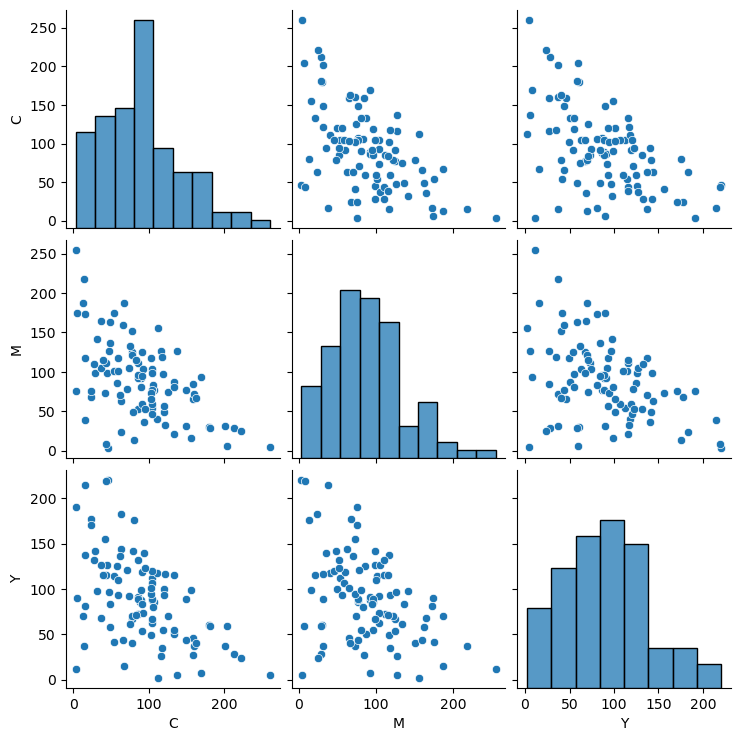

In [6]:
# Create a figure and axis
fig, ax = plt.subplots(figsize=(1, 8))

# Number of colors
num_colors = len(rgb_values)

# Create a circle for each color
for i, rgb in enumerate(rgb_values):
    color = [val / 255 for val in rgb]  # Normalize RGB values to [0, 1] range
    circle = plt.Circle((0.5, num_colors - i - 0.5), 0.5, color=color)
    ax.add_patch(circle)

# Set the limits and remove axes
ax.set_xlim(0, 1)
ax.set_ylim(0, num_colors)
ax.axis('off')

# Display the plot
plt.show()